# Validation model comparison

Saved aggregate records from `results/metrics/` compare neural network, LightGBM, and CatBoost across application-only and application-plus-history features. This notebook reads results without fitting models or loading applicant-level data.

ROC-AUC is the primary metric. Python runs share applicant splits; the historical R logistic regression uses different assignments and raw application preprocessing, so any available baseline record is an unpaired reference. The original baseline report is preserved separately.


In [ ]:
from pathlib import Path
import sys

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "scripts" / "project_data.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Notebook working directory must be inside this repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.comparison_utils import (
    MODEL_NAMES, MODELS, FEATURE_SETS, load_run_records, select_runs,
    results_frame, coverage_frame, history_gains, validation_auc_history,
)
RESULTS_DIR = REPO_ROOT / "results" / "metrics"
SPLIT_STRATEGY = "stratified"
CONFIGURATION = "starter_v1"
SPLIT_HASH = None  # Specify a hash if multiple Python split cohorts exist.
pd.set_option("display.max_columns", 30)


## 1. Result inventory and comparability

Selection uses the latest saved run per model and feature set, rather than the highest score among reruns. Paired comparisons require a shared split fingerprint, matching feature schemas within each feature set, and consistent classification thresholds.

Older records remain visible in the inventory. Missing metrics stay missing, and R baseline records are kept outside paired comparisons.


In [ ]:
all_records = load_run_records(RESULTS_DIR)
selected_records, selected_split_hash = select_runs(
    all_records, strategy=SPLIT_STRATEGY, configuration=CONFIGURATION, split_hash=SPLIT_HASH,
)
comparison = results_frame(selected_records)
paired = comparison[comparison["model"].isin(MODELS)].copy()
baseline = comparison[comparison["model"] == "logistic_regression"].copy()
print(f"Found {len(all_records)} records; selected {len(paired)} paired runs and {len(baseline)} R baseline.")
print("Python split fingerprint:", selected_split_hash)
display(coverage_frame(selected_records))
if baseline.empty:
    print("Baseline metrics are not available in the saved run records.")
inventory = results_frame(all_records)
if not inventory.empty:
    display(inventory[["model_name", "feature_set", "configuration", "created_at_utc", "source_file"]]
            .sort_values(["model_name", "feature_set", "created_at_utc"]).reset_index(drop=True))


Found 6 records; selected 6 paired runs and 0 R baseline.
Python split fingerprint: cba88bf5788aa3a722df0da8fda8c4466dd40d68caa7091caca486f02d063114


,model,feature_set,status
0,Neural network,application_only,available
1,Neural network,application_history,available
2,LightGBM,application_only,available
3,LightGBM,application_history,available
4,CatBoost,application_only,available
5,CatBoost,application_history,available
6,Logistic regression (R baseline),application_only,missing export


Baseline metrics are not available in the saved run records.


,model_name,feature_set,configuration,created_at_utc,source_file
0,CatBoost,application_history,starter_v1,2026-10-06T01:14:03.951338+00:00,catboost_application_history_stratified_starte...
1,CatBoost,application_only,starter_v1,2026-10-06T00:10:57.188385+00:00,catboost_application_only_stratified_starter_v...
2,LightGBM,application_history,starter_v1,2026-10-06T02:50:07.748649+00:00,lightgbm_application_history_stratified_starte...
3,LightGBM,application_only,starter_v1,2026-10-06T02:58:19.293352+00:00,lightgbm_application_only_stratified_starter_v...
4,Neural network,application_history,starter_v1,2026-10-06T01:04:43.284736+00:00,nn_application_history_stratified_starter_v1_2...
5,Neural network,application_only,starter_v1,2026-10-06T00:11:49.433793+00:00,nn_application_only_stratified_starter_v1_2026...


## 2. Validation performance

Scores describe development validation data, not final holdout or Kaggle leaderboard performance. Average precision complements ROC-AUC on this imbalanced task; accuracy is contextualized by the all-negative reference.

Classification metrics use the recorded threshold (0.5 for the initial configurations). Unreported values appear as dashes. R baseline scores, when available, are shown separately.


In [ ]:
score_columns = [
    "model_name", "feature_set", "roc_auc", "average_precision", "log_loss",
    "accuracy", "f1", "precision", "recall", "threshold", "training_minutes",
    "selected_iteration", "validation_rows",
]
ranked = paired.sort_values("roc_auc", ascending=False).reset_index(drop=True)
print("Paired Python runs — descending ROC-AUC:")
display(ranked[score_columns].style.format(precision=4, na_rep="—"))
print("Historical R baseline — unpaired reference:")
if baseline.empty:
    display(pd.DataFrame([{"model": MODEL_NAMES["logistic_regression"],
                           "status": "Baseline metrics not available in saved records."}]))
else:
    display(baseline[score_columns].style.format(precision=4, na_rep="—"))
references = []
for feature_set, group in paired.groupby("feature_set"):
    rate = group["validation_positive_rate"].iloc[0]
    if pd.notna(rate) and 0 < rate < 1:
        references.append({"feature_set": feature_set, "positive_rate": rate,
                           "all_negative_accuracy": 1-rate, "no_signal_AUC": 0.5,
                           "no_signal_expected_AP": rate})
display(pd.DataFrame(references).style.format(precision=4))


Paired Python runs — descending ROC-AUC:


,model_name,feature_set,roc_auc,average_precision,log_loss,accuracy,f1,precision,recall,threshold,training_minutes,selected_iteration,validation_rows
0,CatBoost,application_history,0.7876,0.2852,0.2368,0.9202,0.0855,0.5753,0.0462,0.5000,10.6697,998,46127
1,LightGBM,application_history,0.7853,0.2831,0.2375,0.9199,0.0928,0.5415,0.0508,0.5000,0.9444,367,46127
2,Neural network,application_history,0.7766,0.2659,0.2410,0.9194,0.0096,0.6429,0.0048,0.5000,0.7988,3,46127
3,CatBoost,application_only,0.7599,0.2510,0.2453,0.9198,0.0405,0.5909,0.0209,0.5000,8.3698,829,46127
4,LightGBM,application_only,0.7570,0.2470,0.2462,0.9195,0.0378,0.5407,0.0196,0.5000,0.2968,241,46127
5,Neural network,application_only,0.7486,0.2304,0.2490,0.9193,0.0069,0.5652,0.0035,0.5000,1.1124,8,46127


Historical R baseline — unpaired reference:


,model,status
0,Logistic regression (R baseline),Baseline metrics not available in saved records.


,feature_set,positive_rate,all_negative_accuracy,no_signal_AUC,no_signal_expected_AP
0,application_history,0.0807,0.9193,0.5000,0.0807
1,application_only,0.0807,0.9193,0.5000,0.0807


## 3. History features and training cost

Within-model differences compare the same configuration and applicant split. Positive ROC-AUC/average-precision changes and negative log-loss changes indicate improvement.

These are descriptive single-run comparisons, not significance estimates. Training times depend on hardware and concurrent workload.


,model,application_only_auc,application_history_auc,auc_gain,average_precision_gain,log_loss_change,extra_training_minutes
0,CatBoost,0.7599,0.7876,0.0276,0.0342,-0.0085,2.2999
1,LightGBM,0.7570,0.7853,0.0283,0.0360,-0.0087,0.6476
2,Neural network,0.7486,0.7766,0.0280,0.0355,-0.0080,-0.3136


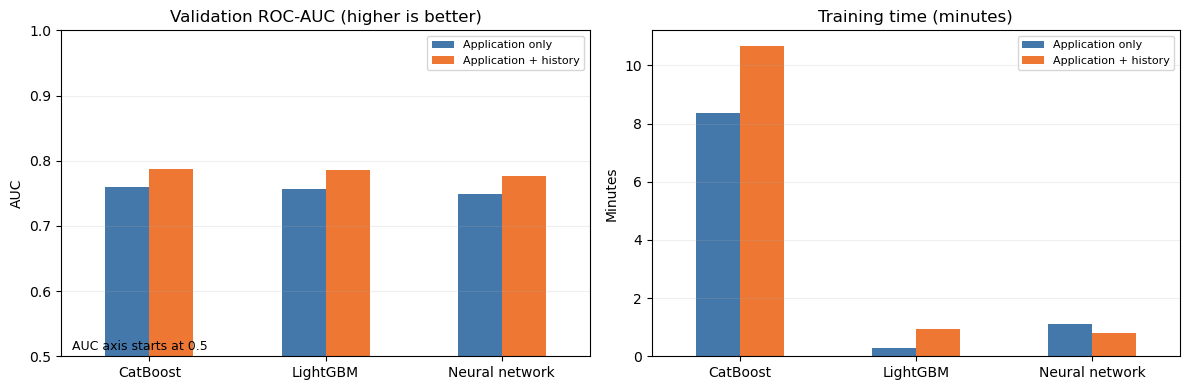

In [ ]:
gains = history_gains(paired)
display(gains.style.format(precision=4, na_rep="—"))
if not paired.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, title in [
        (axes[0], "roc_auc", "Validation ROC-AUC (higher is better)"),
        (axes[1], "training_minutes", "Training time (minutes)"),
    ]:
        wide = paired.pivot(index="model_name", columns="feature_set", values=metric)
        wide = wide.reindex(columns=FEATURE_SETS).dropna(axis=1, how="all")
        wide.rename(columns={"application_only": "Application only",
                             "application_history": "Application + history"}).plot.bar(
            ax=ax, rot=0, color=["#4477AA", "#EE7733"])
        ax.set_title(title)
        ax.set_xlabel("")
        ax.set_ylabel("AUC" if metric == "roc_auc" else "Minutes")
        if metric == "roc_auc":
            ax.set_ylim(0.5, 1.0)
            ax.text(0.02, 0.02, "AUC axis starts at 0.5", transform=ax.transAxes, fontsize=9)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## 4. Learning curves and classification errors

Validation learning curves show model selection over epochs or tree iterations. Dashed lines mark the retained epoch or tree count; these units are not directly comparable across model families.

Confusion counts use the recorded threshold: TN/TP are correct predictions, FP are false alarms, and FN are missed defaults.


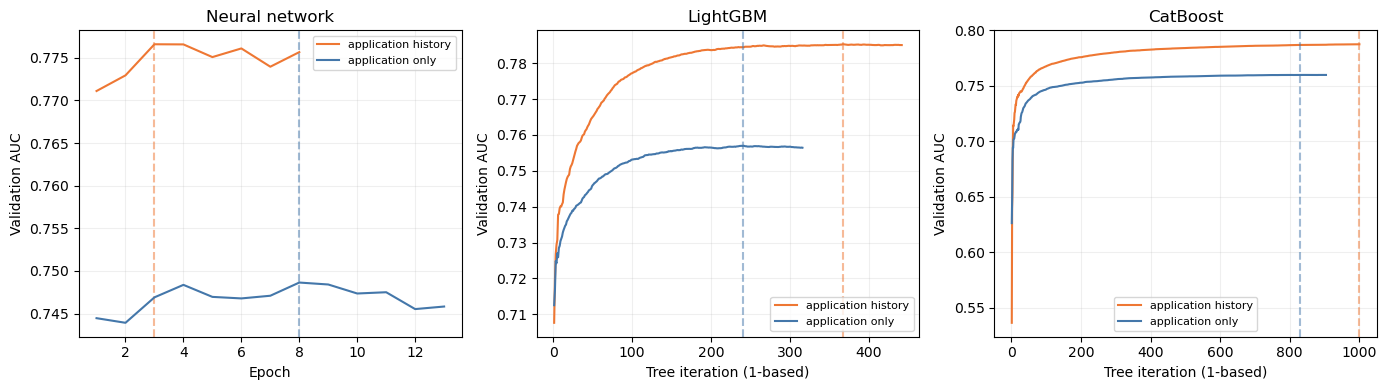

,model,feature_set,comparison_group,threshold,tn,fp,fn,tp
0,CatBoost,application_history,paired Python,0.5,42276,127,3552,172
1,CatBoost,application_only,paired Python,0.5,42349,54,3646,78
2,LightGBM,application_history,paired Python,0.5,42243,160,3535,189
3,LightGBM,application_only,paired Python,0.5,42341,62,3651,73
4,Neural network,application_history,paired Python,0.5,42393,10,3706,18
5,Neural network,application_only,paired Python,0.5,42393,10,3711,13


In [ ]:
if not paired.empty:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    colors = {"application_only": "#4477AA", "application_history": "#EE7733"}
    for ax, model_name in zip(axes, MODELS):
        found = False
        for record in selected_records:
            if record["model"] != model_name:
                continue
            steps, values = validation_auc_history(record)
            if not steps:
                continue
            found = True
            color = colors[record["feature_set"]]
            ax.plot(steps, values, label=record["feature_set"].replace("_", " "), color=color)
            if record.get("selected_iteration") is not None:
                ax.axvline(record["selected_iteration"], color=color, linestyle="--", alpha=0.5)
        ax.set_title(MODEL_NAMES[model_name])
        ax.set_xlabel("Epoch" if model_name == "nn" else "Tree iteration (1-based)")
        ax.set_ylabel("Validation AUC")
        ax.grid(alpha=0.2)
        if found:
            ax.legend(fontsize=8)
        else:
            ax.text(0.5, 0.5, "No saved curve", ha="center", transform=ax.transAxes)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
confusion_rows = []
for record in selected_records:
    counts = record["metrics"].get("confusion_matrix")
    if counts:
        confusion_rows.append({"model": MODEL_NAMES[record["model"]], "feature_set": record["feature_set"],
                               "comparison_group": "unpaired R reference" if record["model"] == "logistic_regression" else "paired Python",
                               "threshold": record["metrics"]["threshold"], **counts})
display(pd.DataFrame(confusion_rows))


## 5. Summary and limitations

The summary is calculated from selected records, including the leading validation score and each model's change after adding history.

Aggregate records support metrics and learning curves. Applicant-level prediction exports are separate inputs for error analysis, fairness slices, ROC/PR curves, or uncertainty estimates. These experiments do not include threshold tuning, cross-validation, a non-random deployment split, or final holdout evaluation.


In [ ]:
if not ranked.empty:
    leader = ranked.iloc[0]
    print(f"Highest paired validation AUC: {leader.model_name} / {leader.feature_set}: {leader.roc_auc:.4f}.")
    if len(ranked) >= 2:
        print(f"Lead over next run: {leader.roc_auc-ranked.iloc[1].roc_auc:.4f} AUC (single-run; no uncertainty estimate).")
    for row in gains.itertuples(index=False):
        print(f"{row.model}: history changed AUC by {row.auc_gain:+.4f}.")
    for record in selected_records:
        if record["model"] not in MODELS:
            continue
        params = record.get("parameters", {})
        cap = params.get("iterations", params.get("n_estimators", params.get("max_epochs")))
        chosen = record.get("selected_iteration")
        if cap and chosen and chosen >= 0.95 * cap:
            print(f"{MODEL_NAMES[record['model']]} / {record['feature_set']}: selected near cap ({chosen}/{cap}).")
    print("Validation comparison only; holdout and competition data were not evaluated.")


Highest paired validation AUC: CatBoost / application_history: 0.7876.
Lead over next run: 0.0023 AUC (single-run; no uncertainty estimate).
CatBoost: history changed AUC by +0.0276.
LightGBM: history changed AUC by +0.0283.
Neural network: history changed AUC by +0.0280.
CatBoost / application_history: selected near cap (998/1000); inspect curve before extending.
Validation comparison only; holdout and competition data were not evaluated.
